# 1. Importation des bibliothèques

Dans cette première étape, nous importons les bibliothèques nécessaires
pour effectuer l'analyse exploratoire, le prétraitement, l'entraînement
des modèles de machine learning et l'évaluation de leurs performances.

Nous utilisons principalement pandas pour manipuler les données,
NumPy pour les opérations numériques, Matplotlib pour les visualisations
et scikit-learn pour construire les modèles.

In [1]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt

# Gestion des avertissements
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Séparation des données
from sklearn.model_selection import train_test_split

# Prétraitement
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Modèles de classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Évaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Importance des variables
from sklearn.inspection import permutation_importance

# Gestion du modèle
import joblib

# Version de scikit-learn
import sklearn

print("Version de pandas :", pd.__version__)
print("Version de NumPy :", np.__version__)
print("Version de scikit-learn :", sklearn.__version__)

Version de pandas : 3.0.6
Version de NumPy : 2.5.3
Version de scikit-learn : 1.9.1


# 2. Chargement des données

Nous chargeons le dataset ShopExpress avec pandas.

Nous affichons ensuite les premières lignes afin de vérifier
que le fichier a été correctement importé.

In [2]:
df = pd.read_csv("shop.csv")

print("Dimensions du dataset :", df.shape)

print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

display(df.head())

Dimensions du dataset : (10999, 18)
Nombre de lignes : 10999
Nombre de colonnes : 18


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Distance_km,Weather_Condition,Traffic_Level,Route_Complexity,Customer_Country,Product_Category
0,1,D,Flight,4,2,177,3,low,F,44,1233,1,3741,Clear,Non applicable,Moderate,Australia,Electronics
1,2,F,Flight,4,5,216,2,low,M,59,3088,1,2501,Rain,Non applicable,Moderate,India,Automotive Accessories
2,3,A,Flight,2,2,183,4,low,M,48,3374,1,3414,Rain,Non applicable,Moderate,Japan,Books & Stationery
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1,4004,Rain,Non applicable,Moderate,United Kingdom,Beauty & Personal Care
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1,970,Rain,Non applicable,Moderate,Canada,Beauty & Personal Care


In [3]:
print(df.columns.tolist())

['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N', 'Distance_km', 'Weather_Condition', 'Traffic_Level', 'Route_Complexity', 'Customer_Country', 'Product_Category']


# 3. Analyse exploratoire des données — EDA

L'analyse exploratoire permet de comprendre la structure du dataset,
de détecter les problèmes de qualité et d'identifier les caractéristiques
qui pourraient être utiles pour la prédiction du risque de retard.

In [4]:
# Informations générales
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10999 entries, 0 to 10998
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   10999 non-null  int64
 1   Warehouse_block      10999 non-null  str  
 2   Mode_of_Shipment     10999 non-null  str  
 3   Customer_care_calls  10999 non-null  int64
 4   Customer_rating      10999 non-null  int64
 5   Cost_of_the_Product  10999 non-null  int64
 6   Prior_purchases      10999 non-null  int64
 7   Product_importance   10999 non-null  str  
 8   Gender               10999 non-null  str  
 9   Discount_offered     10999 non-null  int64
 10  Weight_in_gms        10999 non-null  int64
 11  Reached.on.Time_Y.N  10999 non-null  int64
 12  Distance_km          10999 non-null  int64
 13  Weather_Condition    10999 non-null  str  
 14  Traffic_Level        10999 non-null  str  
 15  Route_Complexity     10999 non-null  str  
 16  Customer_Country     10999 non-nu

In [5]:
# Nombre de lignes et de colonnes
print("Dimensions :", df.shape)

# Noms des colonnes
print("\nColonnes :")
print(df.columns.tolist())

# Types de données
print("\nTypes des variables :")
display(df.dtypes.to_frame("Type de données"))

Dimensions : (10999, 18)

Colonnes :
['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N', 'Distance_km', 'Weather_Condition', 'Traffic_Level', 'Route_Complexity', 'Customer_Country', 'Product_Category']

Types des variables :


,Type de données
ID,int64
Warehouse_block,str
Mode_of_Shipment,str
Customer_care_calls,int64
Customer_rating,int64
Cost_of_the_Product,int64
Prior_purchases,int64
Product_importance,str
Gender,str
Discount_offered,int64


In [6]:
missing_values = df.isnull().sum()

missing_table = pd.DataFrame({
    "Valeurs manquantes": missing_values,
    "Pourcentage (%)": (missing_values / len(df)) * 100
})

display(
    missing_table.sort_values(
        by="Pourcentage (%)",
        ascending=False
    )
)

,Valeurs manquantes,Pourcentage (%)
ID,0,0.0
Warehouse_block,0,0.0
Mode_of_Shipment,0,0.0
Customer_care_calls,0,0.0
Customer_rating,0,0.0
Cost_of_the_Product,0,0.0
Prior_purchases,0,0.0
Product_importance,0,0.0
Gender,0,0.0
Discount_offered,0,0.0


Vérifier les valeurs manquantes

In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values()

if len(missing) > 0:

    plt.figure(figsize=(10, 5))

    missing.plot(kind="barh")

    plt.title("Valeurs manquantes par variable")
    plt.xlabel("Nombre de valeurs manquantes")
    plt.ylabel("Variable")

    plt.tight_layout()
    plt.show()

else:
    print("Aucune valeur manquante détectée.")

Aucune valeur manquante détectée.


Vérifier les doublons

In [8]:
print("Nombre de lignes dupliquées :", df.duplicated().sum())

Nombre de lignes dupliquées : 0


In [9]:
duplicates = df[df.duplicated(keep=False)]

display(duplicates.head(10))

,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N,Distance_km,Weather_Condition,Traffic_Level,Route_Complexity,Customer_Country,Product_Category


Examiner les statistiques descriptives

In [10]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,10999.0,5500.000000,3175.282140,1.0,2750.5,5500.0,8249.5,10999.0
Customer_care_calls,10999.0,4.054459,1.141490,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,3.567597,1.522860,2.0,3.0,3.0,4.0,10.0
Discount_offered,10999.0,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0
Reached.on.Time_Y.N,10999.0,0.596691,0.490584,0.0,0.0,1.0,1.0,1.0
Distance_km,10999.0,3259.549505,2106.486538,19.0,1370.5,3177.0,4878.0,7984.0


In [11]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:

    print("\nVariable :", column)

    display(
        df[column]
        .value_counts(dropna=False)
        .to_frame("Effectif")
    )


Variable : Warehouse_block


C:\Users\nadia\AppData\Local\Temp\ipykernel_77828\2738273051.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


,Effectif
Warehouse_block,
F,3666
D,1834
A,1833
B,1833
C,1833



Variable : Mode_of_Shipment


,Effectif
Mode_of_Shipment,
Ship,7462
Flight,1777
Road,1760



Variable : Product_importance


... (9 outputs left out)


Variable : Customer_Country


,Effectif
Customer_Country,
United States,1991
Canada,1846
India,1528
France,1033
Germany,912
United Kingdom,897
Brazil,795
Japan,675
Australia,670



Variable : Product_Category


,Effectif
Product_Category,
Electronics,2288
Clothing,2114
Home & Kitchen,1840
Beauty & Personal Care,1297
Books & Stationery,992
Sports & Outdoors,971
Toys & Games,873
Automotive Accessories,624


Étudier la variable cible

In [12]:
TARGET = "Reached.on.Time_Y.N"

In [13]:
print("Distribution de la cible :")

display(
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Nombre de commandes")
)

Distribution de la cible :


,Nombre de commandes
Reached.on.Time_Y.N,
0,4436
1,6563


In [14]:
target_percentages = (
    df[TARGET]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(
    target_percentages.to_frame(
        "Pourcentage (%)"
    ).round(2)
)

,Pourcentage (%)
Reached.on.Time_Y.N,
0,40.33
1,59.67


Distribution de la cible

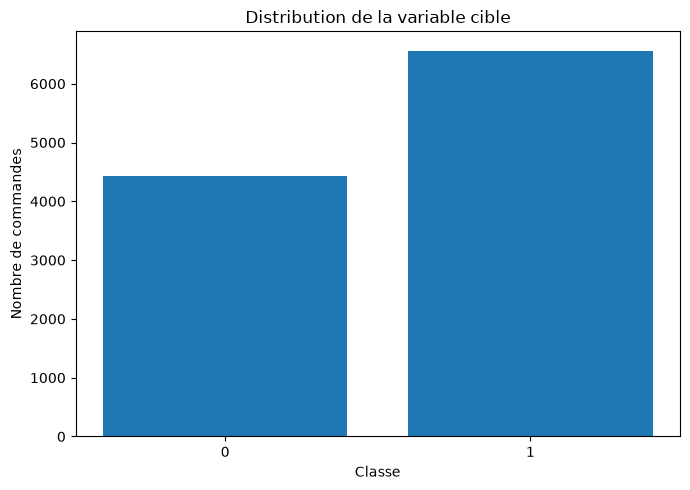

In [15]:
target_counts = df[TARGET].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    target_counts.index.astype(str),
    target_counts.values
)

plt.title("Distribution de la variable cible")
plt.xlabel("Classe")
plt.ylabel("Nombre de commandes")

plt.tight_layout()
plt.show()

Étudier les distributions des variables numériques

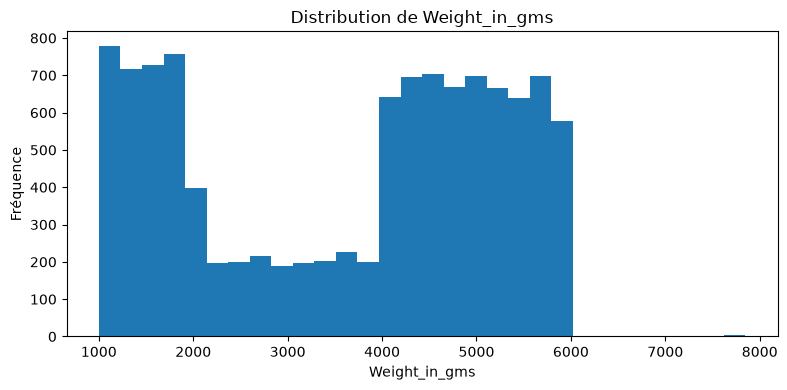

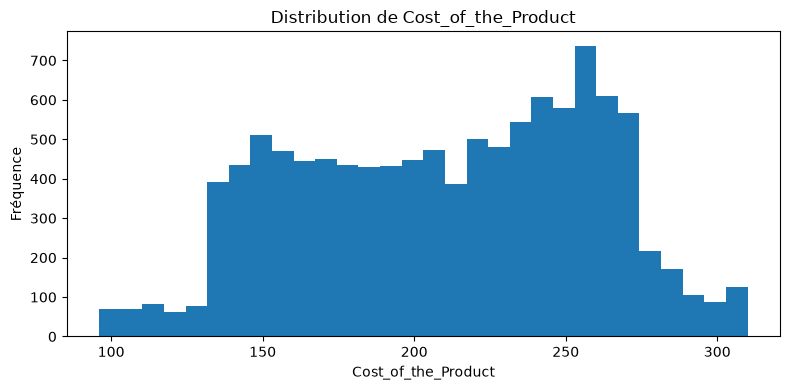

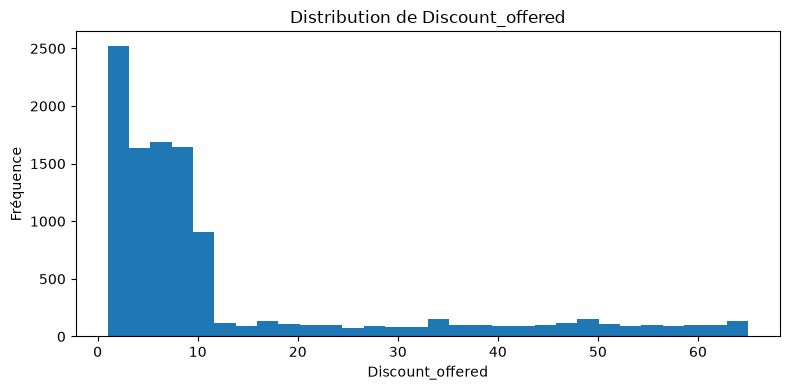

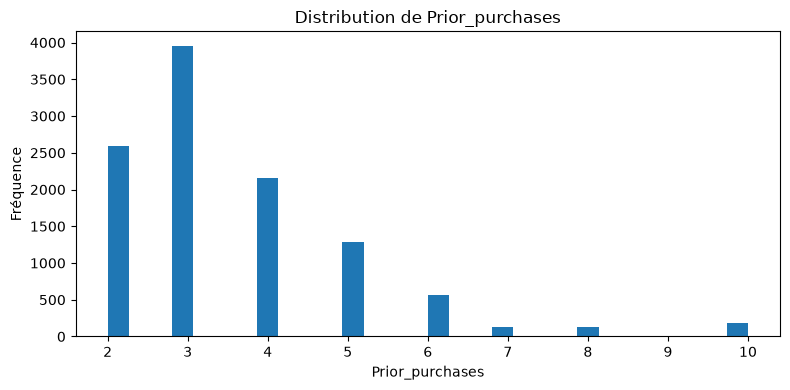

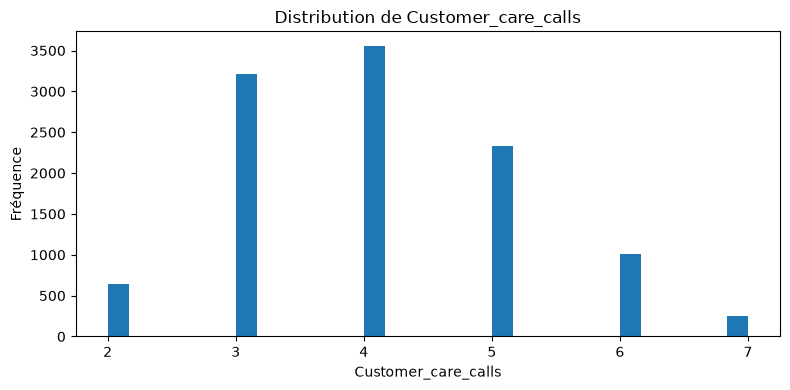

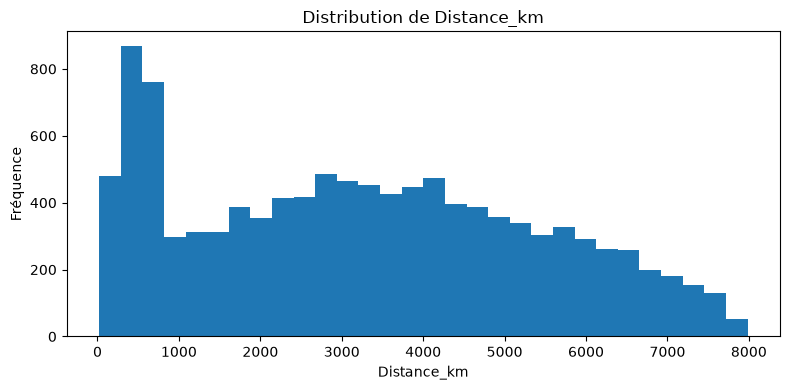

In [16]:
numeric_columns_to_plot = [
    "Weight_in_gms",
    "Cost_of_the_Product",
    "Discount_offered",
    "Prior_purchases",
    "Customer_care_calls",
    "Distance_km"
]

numeric_columns_to_plot = [
    col for col in numeric_columns_to_plot
    if col in df.columns
]

for column in numeric_columns_to_plot:

    plt.figure(figsize=(8, 4))

    plt.hist(
        pd.to_numeric(df[column], errors="coerce").dropna(),
        bins=30
    )

    plt.title(f"Distribution de {column}")
    plt.xlabel(column)
    plt.ylabel("Fréquence")

    plt.tight_layout()
    plt.show()

Répartition des modes d'expédition

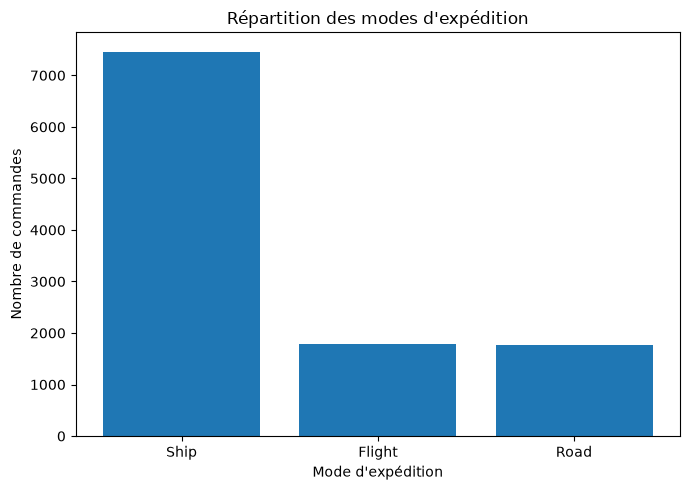

In [17]:
shipment_counts = df["Mode_of_Shipment"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    shipment_counts.index,
    shipment_counts.values
)

plt.title("Répartition des modes d'expédition")
plt.xlabel("Mode d'expédition")
plt.ylabel("Nombre de commandes")

plt.tight_layout()
plt.show()

Catégories de produits

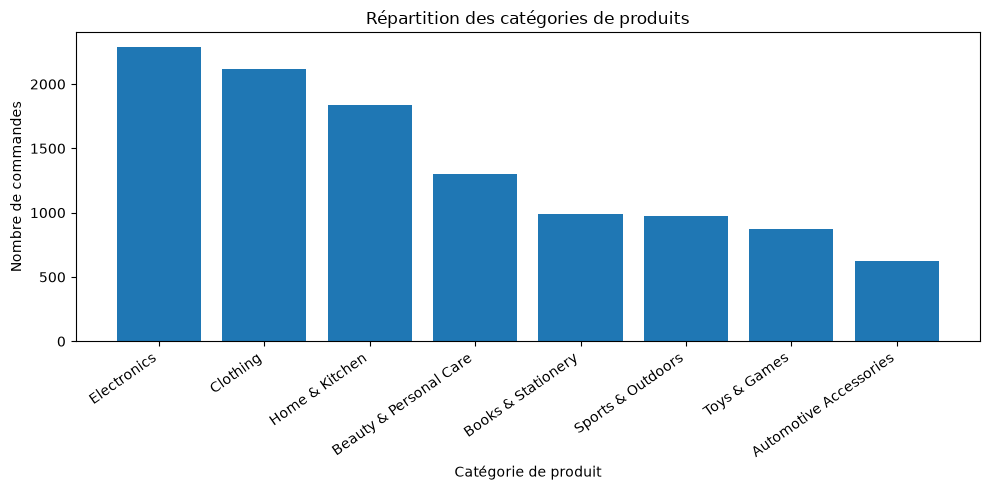

In [18]:
if "Product_Category" in df.columns:

    category_counts = df["Product_Category"].value_counts()

    plt.figure(figsize=(10, 5))

    plt.bar(
        category_counts.index,
        category_counts.values
    )

    plt.title("Répartition des catégories de produits")
    plt.xlabel("Catégorie de produit")
    plt.ylabel("Nombre de commandes")

    plt.xticks(rotation=35, ha="right")

    plt.tight_layout()
    plt.show()

Proportion de la classe 1 par mode d'expédition

In [19]:
shipment_target = pd.crosstab(
    df["Mode_of_Shipment"],
    df[TARGET],
    normalize="index"
) * 100

display(shipment_target.round(2))

Reached.on.Time_Y.N,0,1
Mode_of_Shipment,,
Flight,39.84,60.16
Road,41.19,58.81
Ship,40.24,59.76


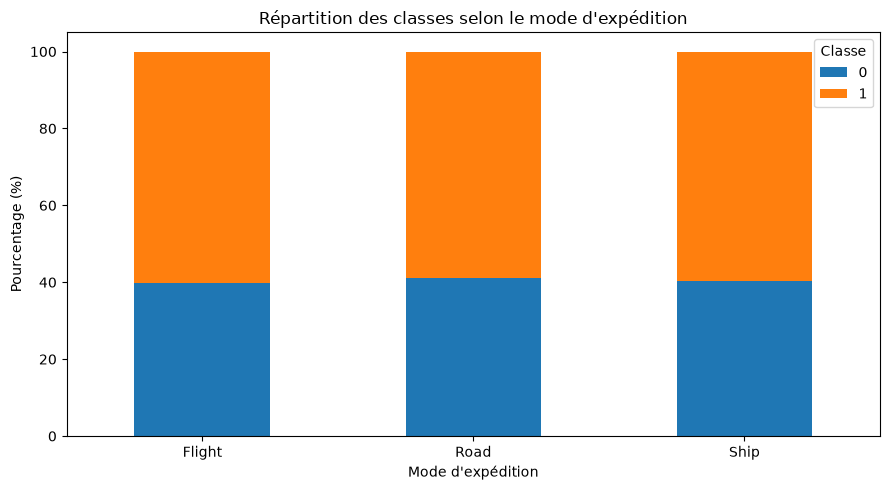

In [20]:
shipment_target.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Répartition des classes selon le mode d'expédition")
plt.xlabel("Mode d'expédition")
plt.ylabel("Pourcentage (%)")

plt.legend(title="Classe")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Étudier les catégories de produits

Reached.on.Time_Y.N,0,1
Product_Category,,
Automotive Accessories,43.91,56.09
Beauty & Personal Care,38.86,61.14
Books & Stationery,40.32,59.68
Clothing,40.40,59.60
Electronics,38.81,61.19
Home & Kitchen,42.72,57.28
Sports & Outdoors,41.61,58.39
Toys & Games,37.34,62.66


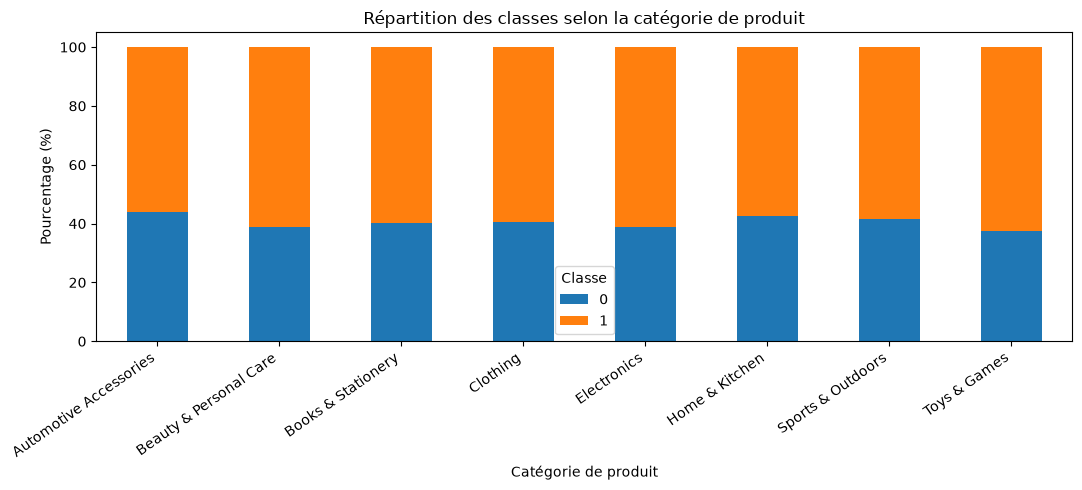

In [21]:
if "Product_Category" in df.columns:

    category_target = pd.crosstab(
        df["Product_Category"],
        df[TARGET],
        normalize="index"
    ) * 100

    display(category_target.round(2))

    category_target.plot(
        kind="bar",
        stacked=True,
        figsize=(11, 5)
    )

    plt.title("Répartition des classes selon la catégorie de produit")
    plt.xlabel("Catégorie de produit")
    plt.ylabel("Pourcentage (%)")

    plt.legend(title="Classe")
    plt.xticks(rotation=35, ha="right")

    plt.tight_layout()
    plt.show()

# 4. Préparation des données

Nous séparons la variable cible des variables explicatives.

La variable cible représente ce que le modèle doit prédire.

Les variables explicatives correspondent aux caractéristiques utilisées
pour effectuer la prédiction.

In [22]:
TARGET = "Reached.on.Time_Y.N"

# Vérifier que la cible existe
assert TARGET in df.columns, "La variable cible est absente."

# Exclure les lignes sans cible connue
df_model = df.dropna(subset=[TARGET]).copy()

# Vérifier les valeurs de la cible
print("Valeurs de la cible :")
print(sorted(df_model[TARGET].unique()))

Valeurs de la cible :
[np.int64(0), np.int64(1)]


In [23]:
classes = set(df_model[TARGET].unique())

if not classes.issubset({0, 1, 0.0, 1.0}):
    raise ValueError(
        f"La cible doit être codée en 0 et 1. Valeurs détectées : {classes}"
    )

df_model[TARGET] = df_model[TARGET].astype(int)

Identifier les colonnes à exclure

In [24]:
columns_to_drop = [
    "ID"
]

columns_to_drop = [
    col for col in columns_to_drop
    if col in df_model.columns
]

print("Colonnes exclues :", columns_to_drop)

Colonnes exclues : ['ID']


Définir les variables originales et enrichies

Nous allons préparer deux configurations expérimentales.

Configuration A : les variables originales du dataset.

Configuration B : les variables originales auxquelles s'ajoutent les nouvelles colonnes.

In [25]:
added_features = [
    "Distance_km",
    "Weather_Condition",
    "Traffic_Level",
    "Route_Complexity",
    "Customer_Country",
    "Product_Category"
]

# Garder uniquement les colonnes ajoutées présentes dans le fichier
added_features = [
    col for col in added_features
    if col in df_model.columns
]

original_features = [
    col for col in df_model.columns
    if col not in [TARGET] + columns_to_drop + added_features
]

enriched_features = [
    col for col in df_model.columns
    if col not in [TARGET] + columns_to_drop
]

print("Variables originales :")
print(original_features)

print("\nVariables ajoutées :")
print(added_features)

print("\nNombre de variables originales :", len(original_features))
print("Nombre de variables enrichies :", len(enriched_features))

Variables originales :
['Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms']

Variables ajoutées :
['Distance_km', 'Weather_Condition', 'Traffic_Level', 'Route_Complexity', 'Customer_Country', 'Product_Category']

Nombre de variables originales : 10
Nombre de variables enrichies : 16


# 5. Séparation des données

Nous séparons le dataset en trois ensembles indépendants :
entraînement, validation et test.

Nous utilisons stratify=y afin de préserver approximativement
la proportion des classes dans les trois ensembles.

Le jeu de test ne sera pas utilisé pour choisir le modèle.

In [26]:
def split_data(data, feature_columns, target_column, random_state=42):

    X = data[feature_columns].copy()
    y = data[target_column].copy()

    # 70 % pour l'entraînement et 30 % temporairement
    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=random_state,
        stratify=y
    )

    # Diviser les 30 % restants en 15 % validation et 15 % test
    X_valid, X_test, y_valid, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=random_state,
        stratify=y_temp
    )

    return X_train, X_valid, X_test, y_train, y_valid, y_test

Nous créons maintenant les ensembles pour notre première expérience.

In [27]:
splits_enriched = split_data(
    df_model,
    enriched_features,
    TARGET
)

X_train, X_valid, X_test, y_train, y_valid, y_test = splits_enriched

print("Entraînement :", X_train.shape)
print("Validation :", X_valid.shape)
print("Test :", X_test.shape)

Entraînement : (7699, 16)
Validation : (1650, 16)
Test : (1650, 16)


Vérifions les proportions.

In [28]:
split_summary = pd.DataFrame({
    "Ensemble": [
        "Entraînement",
        "Validation",
        "Test"
    ],
    "Nombre de lignes": [
        len(y_train),
        len(y_valid),
        len(y_test)
    ],
    "Proportion classe 1 (%)": [
        y_train.mean() * 100,
        y_valid.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(2))

,Ensemble,Nombre de lignes,Proportion classe 1 (%)
0,Entraînement,7699,59.67
1,Validation,1650,59.70
2,Test,1650,59.64


Répartition des ensembles

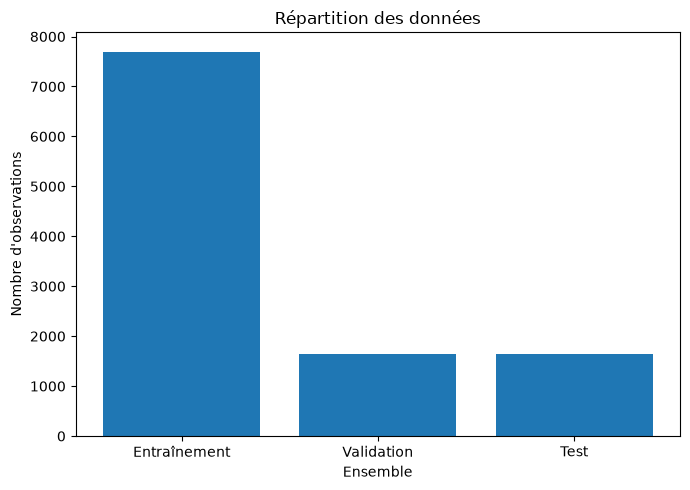

In [29]:
plt.figure(figsize=(7, 5))

plt.bar(
    split_summary["Ensemble"],
    split_summary["Nombre de lignes"]
)

plt.title("Répartition des données")
plt.xlabel("Ensemble")
plt.ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

# 6. Prétraitement des variables

Nous utilisons ColumnTransformer pour appliquer des transformations
différentes selon le type de variable.

Les variables numériques sont imputées puis standardisées.

Les variables catégorielles sont imputées puis encodées avec OneHotEncoder.

Le prétraitement est intégré au Pipeline du modèle. Ainsi, les transformations
sont apprises uniquement sur les données d'entraînement, ce qui limite
les risques de fuite de données.

In [30]:
def build_preprocessor(X):

    numeric_features = X.select_dtypes(
        include=["number", "bool"]
    ).columns.tolist()

    categorical_features = [
        col for col in X.columns
        if col not in numeric_features
    ]

    # Pipeline numérique
    numeric_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    # Pipeline catégoriel
    categorical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ])

    # Combinaison des deux pipelines
    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ])

    return preprocessor

Vérifions les types de variables.

In [31]:
preprocessor = build_preprocessor(X_train)

print("Variables numériques :")
print(X_train.select_dtypes(include=["number", "bool"]).columns.tolist())

print("\nVariables catégorielles :")
print(
    X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()
)

Variables numériques :
['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms', 'Distance_km']

Variables catégorielles :
['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender', 'Weather_Condition', 'Traffic_Level', 'Route_Complexity', 'Customer_Country', 'Product_Category']


# ÉTAPE 7 — Entraîner trois modèles de classification

C'est maintenant que commence réellement l'entraînement du machine learning.

Nous allons tester trois modèles :

Régression logistique ;
Arbre de décision ;
Random Forest.

Nous allons commencer avec des paramètres raisonnables, puis comparer les résultats.

# Modèle 1 — Régression logistique

La régression logistique est un modèle de classification.

Même si son nom contient « régression », elle peut prédire une classe binaire.

Elle estime la probabilité qu'une observation appartienne à la classe 1.

In [32]:
logistic_model = Pipeline([
    (
        "preprocessor",
        build_preprocessor(X_train)
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])

logistic_model.fit(X_train, y_train)

print("Régression logistique entraînée.")

Régression logistique entraînée.


# Modèle 2 — Arbre de décision

Un arbre de décision apprend une succession de règles pour séparer les observations en différentes classes.

In [33]:
tree_model = Pipeline([
    (
        "preprocessor",
        build_preprocessor(X_train)
    ),
    (
        "model",
        DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=20,
            random_state=42
        )
    )
])

tree_model.fit(X_train, y_train)

print("Arbre de décision entraîné.")

Arbre de décision entraîné.


# Modèle 3 — Random Forest

Random Forest combine plusieurs arbres de décision.

Chaque arbre apprend à partir d'un échantillon des données et d'une sélection de variables.

Les prédictions des arbres sont ensuite combinées.

In [34]:
random_forest_model = Pipeline([
    (
        "preprocessor",
        build_preprocessor(X_train)
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        )
    )
])

random_forest_model.fit(X_train, y_train)

print("Random Forest entraîné.")

Random Forest entraîné.


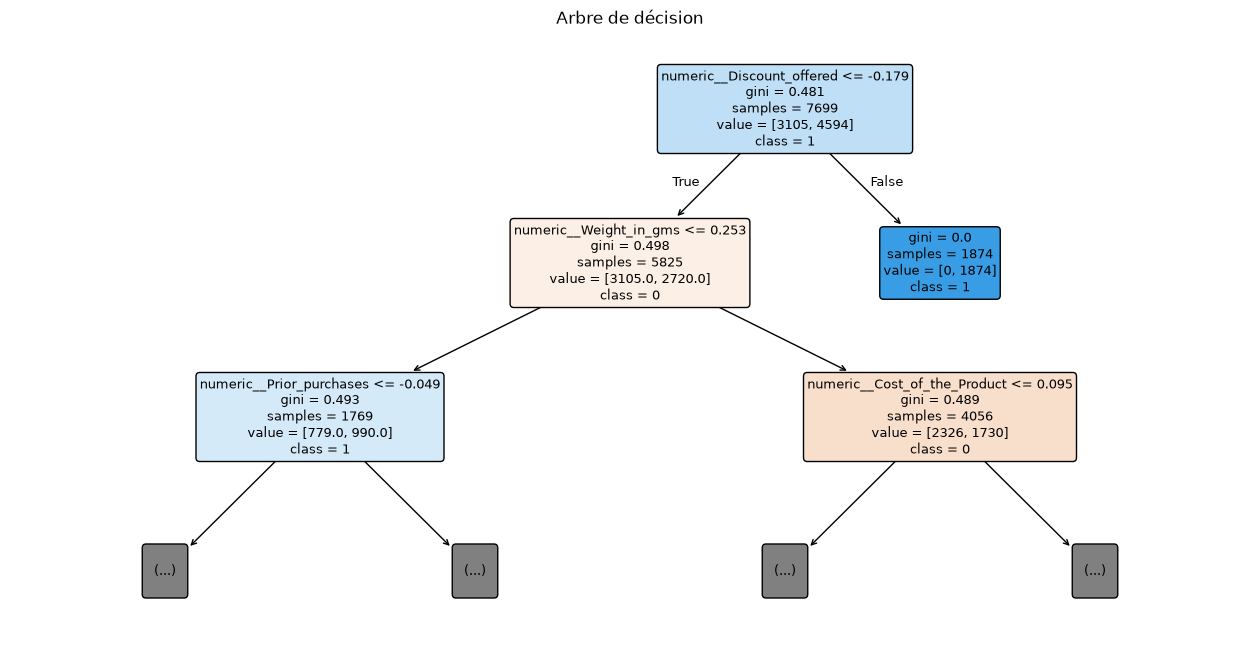

In [37]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Récupérer le modèle entraîné
preprocessor = tree_model.named_steps["preprocessor"]
decision_tree = tree_model.named_steps["model"]

# Noms des variables après prétraitement
feature_names = preprocessor.get_feature_names_out()

# Afficher l'arbre
plt.figure(figsize=(16, 8))

plot_tree(
    decision_tree,
    feature_names=feature_names,
    class_names=[str(c) for c in decision_tree.classes_],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)

plt.title("Arbre de décision")
plt.show()

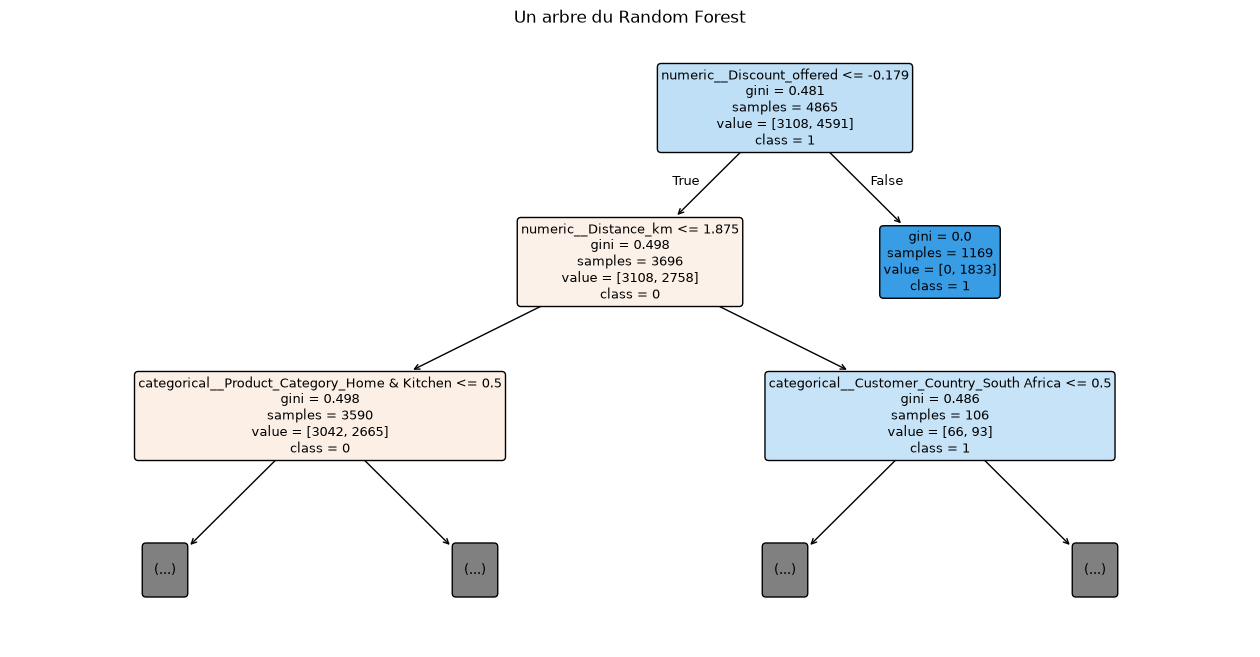

In [38]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Récupérer le modèle entraîné
preprocessor = random_forest_model.named_steps["preprocessor"]
random_forest = random_forest_model.named_steps["model"]

feature_names = preprocessor.get_feature_names_out()

# Sélectionner un arbre
one_tree = random_forest.estimators_[0]

plt.figure(figsize=(16, 8))

plot_tree(
    one_tree,
    feature_names=feature_names,
    class_names=[str(c) for c in random_forest.classes_],
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=9
)

plt.title("Un arbre du Random Forest")
plt.show()